In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Cargar datos
df = pd.read_csv('train.csv')

# Filtrar solo la biomasa verde total (GDM_g)
gdm = df[df['target_name'] == 'GDM_g'].copy().reset_index(drop=True)

# Crear variable derivada y convertir a kg/ha
gdm['NDVI_x_Altura'] = gdm['Pre_GSHH_NDVI'] * gdm['Height_Ave_cm']
gdm['biomasa_kg_ha'] = gdm['target'] * 47.619

print(f"Muestras GDM_g: {len(gdm)}")
print(gdm[['Pre_GSHH_NDVI','Height_Ave_cm','NDVI_x_Altura','biomasa_kg_ha']].describe().round(2))

Muestras GDM_g: 357
       Pre_GSHH_NDVI  Height_Ave_cm  NDVI_x_Altura  biomasa_kg_ha
count         357.00         357.00         357.00         357.00
mean            0.66           7.60           5.37        1584.49
std             0.15          10.29           7.88        1187.42
min             0.16           1.00           0.16          49.52
25%             0.56           3.00           1.64         763.15
50%             0.69           4.00           2.84        1290.87
75%             0.77           7.00           5.02        2079.79
max             0.91          70.00          58.10        7523.02


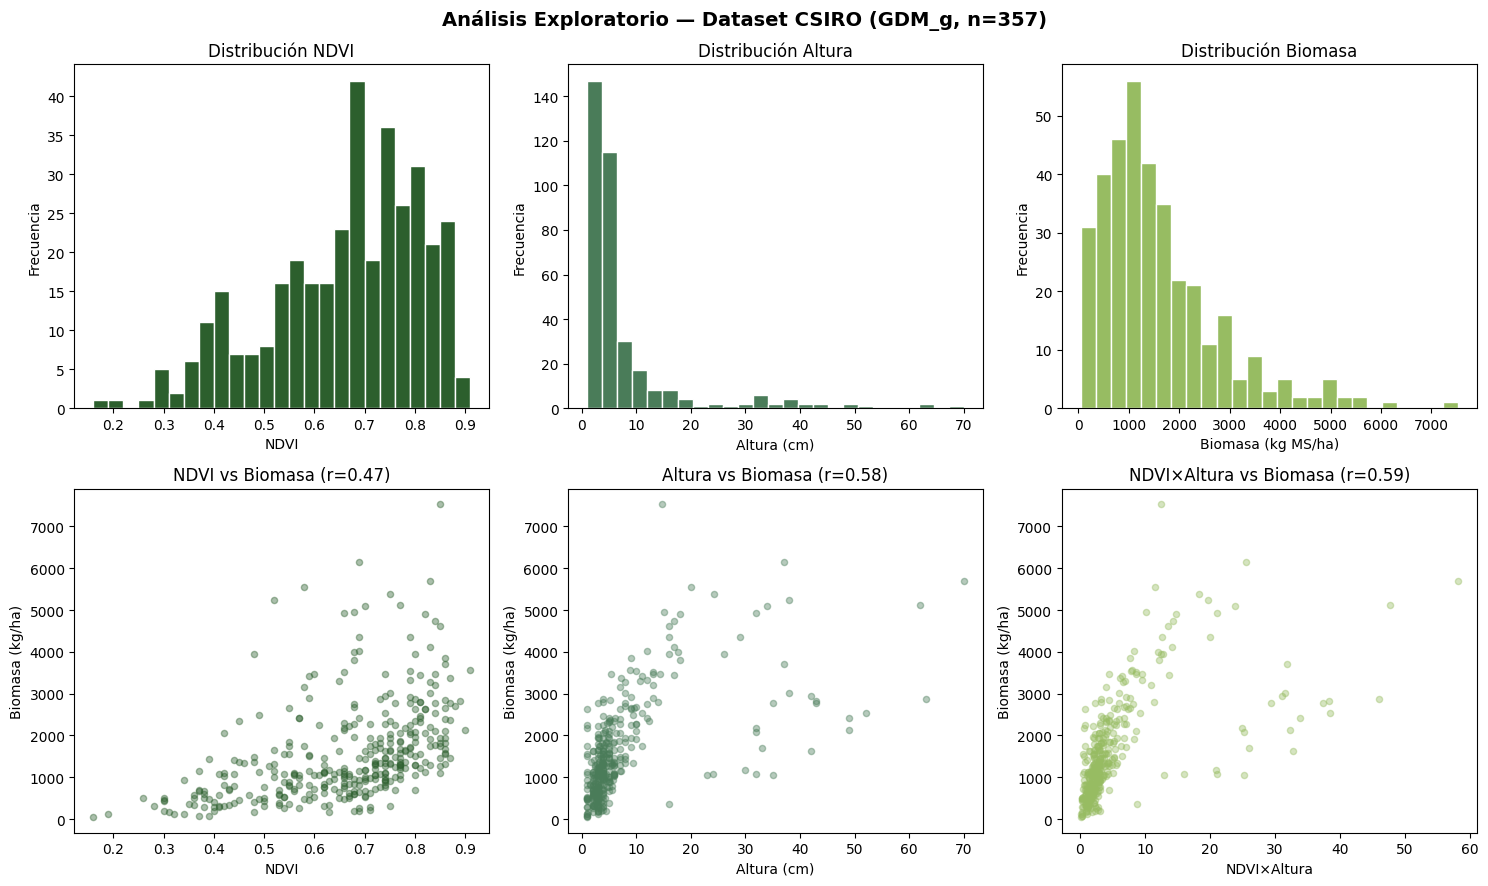


Correlaciones con biomasa:
  NDVI:         r = 0.467
  Altura:       r = 0.583
  NDVI×Altura:  r = 0.589


In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
fig.suptitle('Análisis Exploratorio — Dataset CSIRO (GDM_g, n=357)', fontsize=14, fontweight='bold')

# Histogramas
axes[0,0].hist(gdm['Pre_GSHH_NDVI'], bins=25, color='#2C5F2D', edgecolor='white')
axes[0,0].set_title('Distribución NDVI'); axes[0,0].set_xlabel('NDVI'); axes[0,0].set_ylabel('Frecuencia')

axes[0,1].hist(gdm['Height_Ave_cm'], bins=25, color='#4A7C59', edgecolor='white')
axes[0,1].set_title('Distribución Altura'); axes[0,1].set_xlabel('Altura (cm)'); axes[0,1].set_ylabel('Frecuencia')

axes[0,2].hist(gdm['biomasa_kg_ha'], bins=25, color='#97BC62', edgecolor='white')
axes[0,2].set_title('Distribución Biomasa'); axes[0,2].set_xlabel('Biomasa (kg MS/ha)'); axes[0,2].set_ylabel('Frecuencia')

# Correlaciones
r_ndvi = gdm['Pre_GSHH_NDVI'].corr(gdm['biomasa_kg_ha'])
r_alt  = gdm['Height_Ave_cm'].corr(gdm['biomasa_kg_ha'])
r_prod = gdm['NDVI_x_Altura'].corr(gdm['biomasa_kg_ha'])

axes[1,0].scatter(gdm['Pre_GSHH_NDVI'], gdm['biomasa_kg_ha'], alpha=0.4, color='#2C5F2D', s=20)
axes[1,0].set_title(f'NDVI vs Biomasa (r={r_ndvi:.2f})'); axes[1,0].set_xlabel('NDVI'); axes[1,0].set_ylabel('Biomasa (kg/ha)')

axes[1,1].scatter(gdm['Height_Ave_cm'], gdm['biomasa_kg_ha'], alpha=0.4, color='#4A7C59', s=20)
axes[1,1].set_title(f'Altura vs Biomasa (r={r_alt:.2f})'); axes[1,1].set_xlabel('Altura (cm)'); axes[1,1].set_ylabel('Biomasa (kg/ha)')

axes[1,2].scatter(gdm['NDVI_x_Altura'], gdm['biomasa_kg_ha'], alpha=0.4, color='#97BC62', s=20)
axes[1,2].set_title(f'NDVI×Altura vs Biomasa (r={r_prod:.2f})'); axes[1,2].set_xlabel('NDVI×Altura'); axes[1,2].set_ylabel('Biomasa (kg/ha)')

plt.tight_layout()
plt.savefig('eda_pasturametrics.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"\nCorrelaciones con biomasa:")
print(f"  NDVI:         r = {r_ndvi:.3f}")
print(f"  Altura:       r = {r_alt:.3f}")
print(f"  NDVI×Altura:  r = {r_prod:.3f}")

In [ ]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from xgboost import XGBRegressor

# Variables de entrada y objetivo
X = gdm[['Pre_GSHH_NDVI', 'Height_Ave_cm', 'NDVI_x_Altura']]
y = gdm['biomasa_kg_ha']

# División 75% entrenamiento / 25% prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)
print(f"Entrenamiento: {len(X_train)} muestras")
print(f"Prueba:        {len(X_test)} muestras\n")

def evaluar_modelo(nombre, modelo):
    # Entrenar
    modelo.fit(X_train, y_train)
    pred = modelo.predict(X_test)

    # Métricas sobre conjunto de prueba
    r2   = r2_score(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    mae  = mean_absolute_error(y_test, pred)

    # Validación cruzada (más robusta con pocos datos)
    cv = cross_val_score(modelo, X, y, cv=5, scoring='r2')

    print(f"═══ {nombre} ═══")
    print(f"  R²   (prueba):    {r2:.3f}")
    print(f"  RMSE (prueba):    {rmse:.1f} kg/ha")
    print(f"  MAE  (prueba):    {mae:.1f} kg/ha")
    print(f"  R²   (CV 5-fold): {cv.mean():.3f} ± {cv.std():.3f}")
    print(f"  Importancia variables:")
    print(f"    NDVI:        {modelo.feature_importances_[0]:.2f}")
    print(f"    Altura:      {modelo.feature_importances_[1]:.2f}")
    print(f"    NDVI×Altura: {modelo.feature_importances_[2]:.2f}\n")

    return {'nombre': nombre, 'modelo': modelo, 'pred': pred,
            'r2': r2, 'rmse': rmse, 'mae': mae,
            'cv_mean': cv.mean(), 'cv_std': cv.std()}

# Entrenar ambos
rf  = RandomForestRegressor(n_estimators=100, random_state=42)
xgb = XGBRegressor(n_estimators=100, random_state=42, learning_rate=0.1, verbosity=0)

resultado_rf  = evaluar_modelo("RANDOM FOREST", rf)
resultado_xgb = evaluar_modelo("XGBOOST", xgb)

# Elegir ganador por R² de validación cruzada (más confiable)
ganador = resultado_rf if resultado_rf['cv_mean'] >= resultado_xgb['cv_mean'] else resultado_xgb
print("="*40)
print(f"GANADOR: {ganador['nombre']}")
print(f"(elegido por R² de validación cruzada)")
print("="*40)

Entrenamiento: 267 muestras
Prueba:        90 muestras

═══ RANDOM FOREST ═══
  R²   (prueba):    0.283
  RMSE (prueba):    891.0 kg/ha
  MAE  (prueba):    565.1 kg/ha
  R²   (CV 5-fold): 0.572 ± 0.051
  Importancia variables:
    NDVI:        0.12
    Altura:      0.24
    NDVI×Altura: 0.64

═══ XGBOOST ═══
  R²   (prueba):    0.149
  RMSE (prueba):    970.8 kg/ha
  MAE  (prueba):    621.1 kg/ha
  R²   (CV 5-fold): 0.462 ± 0.077
  Importancia variables:
    NDVI:        0.08
    Altura:      0.09
    NDVI×Altura: 0.84

GANADOR: RANDOM FOREST
(elegido por R² de validación cruzada)


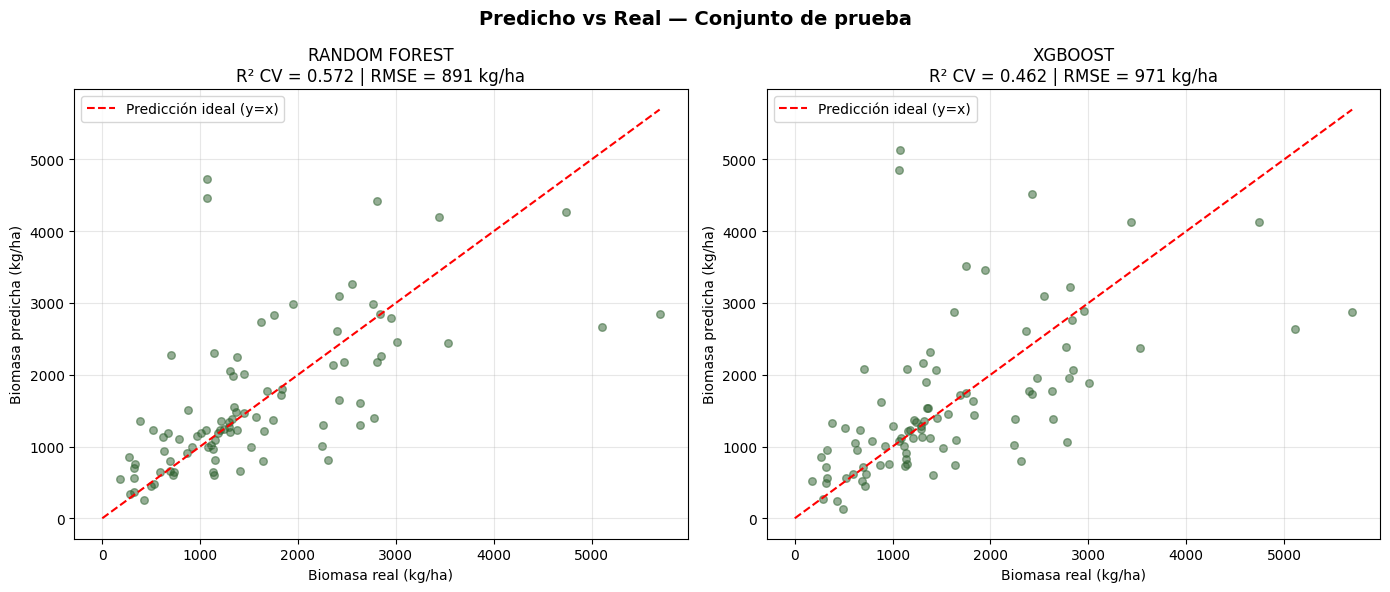

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Predicho vs Real — Conjunto de prueba', fontsize=14, fontweight='bold')

for ax, res in zip(axes, [resultado_rf, resultado_xgb]):
    ax.scatter(y_test, res['pred'], alpha=0.5, color='#2C5F2D', s=30)
    # Línea ideal y=x
    lims = [0, max(y_test.max(), res['pred'].max())]
    ax.plot(lims, lims, 'r--', linewidth=1.5, label='Predicción ideal (y=x)')
    ax.set_xlabel('Biomasa real (kg/ha)')
    ax.set_ylabel('Biomasa predicha (kg/ha)')
    ax.set_title(f"{res['nombre']}\nR² CV = {res['cv_mean']:.3f} | RMSE = {res['rmse']:.0f} kg/ha")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('predicho_vs_real.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
import joblib
import pandas as pd
import os

# Entrenar el modelo final con TODOS los datos disponibles
# (para producción se usa todo el dataset, no solo el 75%)
modelo_final = RandomForestRegressor(n_estimators=100, random_state=42)
modelo_final.fit(X, y)

# Guardar con compresión para que ocupe menos en la RPi
joblib.dump(modelo_final, 'modelo_pasturametrics.pkl', compress=3)

# Verificar tamaño del archivo
tam = os.path.getsize('modelo_pasturametrics.pkl') / 1024
print(f"Modelo guardado: modelo_pasturametrics.pkl")
print(f"Tamaño: {tam:.1f} KB")

# Prueba rápida de que el modelo guardado funciona
modelo_cargado = joblib.load('modelo_pasturametrics.pkl')

ejemplo_ndvi = 0.70
ejemplo_altura = 15.0
ejemplo = pd.DataFrame(
    [[ejemplo_ndvi, ejemplo_altura, ejemplo_ndvi * ejemplo_altura]],
    columns=['Pre_GSHH_NDVI', 'Height_Ave_cm', 'NDVI_x_Altura']
)
prediccion = modelo_cargado.predict(ejemplo)

print(f"\nPrueba de predicción:")
print(f"  NDVI={ejemplo_ndvi}, Altura={ejemplo_altura}cm")
print(f"  Biomasa estimada: {prediccion[0]:.0f} kg MS/ha")

Modelo guardado: modelo_pasturametrics.pkl
Tamaño: 769.9 KB

Prueba de predicción:
  NDVI=0.7, Altura=15.0cm
  Biomasa estimada: 4405 kg MS/ha


In [ ]:
from google.colab import files
files.download('modelo_pasturametrics.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>